<a href="https://colab.research.google.com/github/suhailabdulwasi/walmart-hurricane-project/blob/main/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [13]:
import pandas as pd

BASE = (
    "https://raw.githubusercontent.com/jasontpv/DS2002FA26/"
    "main/notebooks/06-midterm-walmart/data/"
)

sales_raw = pd.read_csv(BASE + "walmart_transactions.csv")
catalog = pd.read_csv(BASE + "product_catalog.csv")
stores = pd.read_csv(BASE + "store_locations.csv")

sales_clean = sales_raw.drop_duplicates().copy()

sales_clean["timestamp"] = pd.to_datetime(
    sales_clean["timestamp"], format="mixed", errors="coerce"
)

sales_clean["quantity"] = pd.to_numeric(
    sales_clean["quantity"], errors="coerce"
)

sales_clean["unit_price"] = pd.to_numeric(
    sales_clean["unit_price"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

sales_clean["store_id"] = (
    sales_clean["store_id"].astype("string").str.strip().str.upper()
)

print("Rows loaded:", len(sales_raw))
print("Rows after removing exact duplicates:", len(sales_clean))

Rows loaded: 25562
Rows after removing exact duplicates: 25532


In [14]:
category_map = {
    "alcohol": "Alcoholic Beverages",
    "alcoholic beverages": "Alcoholic Beverages",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods": "Breakfast Foods",
    "electronics": "Electronics",
    "emergency": "Emergency Supplies",
    "emergency supplies": "Emergency Supplies",
    "entertainment": "Games & Entertainment",
    "games & entertainment": "Games & Entertainment",
    "groceries": "Grocery",
    "grocery": "Grocery",
    "health": "Health & Wellness",
    "health & wellness": "Health & Wellness",
    "household": "Household Essentials",
    "household essentials": "Household Essentials",
    "snacks": "Snacks"
}

analysis_sales = sales_clean.copy()

analysis_sales["category_clean"] = (
    analysis_sales["category"]
    .astype("string").str.strip().str.lower()
    .map(category_map)
)

# Exclude rows that cannot support daily unit comparisons.
valid = (
    analysis_sales["timestamp"].notna()
    & analysis_sales["category_clean"].notna()
    & analysis_sales["quantity"].notna()
    & analysis_sales["quantity"].ge(0)
)

print("Rows excluded from analysis:", int((~valid).sum()))
analysis_sales = analysis_sales.loc[valid].copy()
analysis_sales["date"] = analysis_sales["timestamp"].dt.normalize()

baseline_start = pd.Timestamp("2024-09-05")
baseline_end = pd.Timestamp("2024-09-18")
surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")
landfall = pd.Timestamp("2024-09-26")

daily_units = (
    analysis_sales.groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(pd.date_range("2024-09-01", "2024-09-30"), fill_value=0)
)

baseline_avg = daily_units.loc[baseline_start:baseline_end].mean()
surge_avg = daily_units.loc[surge_start:surge_end].mean()

q1_results = pd.DataFrame({
    "baseline_units_per_day": baseline_avg,
    "surge_units_per_day": surge_avg,
    "multiple": surge_avg / baseline_avg.replace(0, float("nan"))
})

q1_results["percent_increase"] = (q1_results["multiple"] - 1) * 100
q1_results = q1_results.sort_values("multiple", ascending=False)

top_category = q1_results.index[0]
q1_multiple = q1_results.iloc[0]["multiple"]

print("Baseline: September 5–18, 2024 (14 days)")
print("Surge: September 19–25, 2024 (7 days)")
print("Measure: average units sold per day")
display(q1_results.round(2))

Rows excluded from analysis: 1011
Baseline: September 5–18, 2024 (14 days)
Surge: September 19–25, 2024 (7 days)
Measure: average units sold per day


,baseline_units_per_day,surge_units_per_day,multiple,percent_increase
category_clean,,,,
Breakfast Foods,92.29,376.86,4.08,308.36
Emergency Supplies,385.64,1006.43,2.61,160.97
Electronics,74.14,175.86,2.37,137.19
Alcoholic Beverages,64.86,138.86,2.14,114.10
Games & Entertainment,109.43,228.57,2.09,108.88
Health & Wellness,45.50,95.00,2.09,108.79
Household Essentials,91.43,176.29,1.93,92.81
Grocery,178.36,306.57,1.72,71.89
Baby Products,88.93,133.71,1.50,50.36


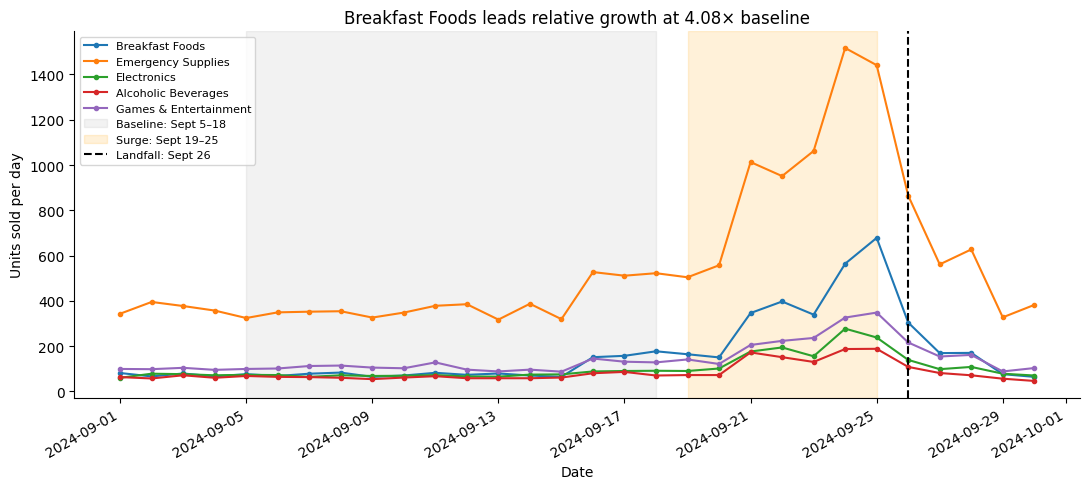

In [15]:
import matplotlib.pyplot as plt

top5 = q1_results.head(5).index

fig, ax = plt.subplots(figsize=(11, 5))

for category in top5:
    ax.plot(
        daily_units.index,
        daily_units[category],
        marker="o",
        markersize=3,
        label=category
    )

ax.axvspan(baseline_start, baseline_end,
           color="gray", alpha=0.1, label="Baseline: Sept 5–18")
ax.axvspan(surge_start, surge_end,
           color="orange", alpha=0.15, label="Surge: Sept 19–25")
ax.axvline(landfall, color="black", linestyle="--",
           label="Landfall: Sept 26")

ax.set_title(
    f"{top_category} leads relative growth at {q1_multiple:.2f}× baseline"
)
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Q1 answer: Breakfast Foods had the largest relative surge, increasing from 92.29 units per day during September 5–18 to 376.86 during September 19–25, a 4.08× multiple, or 308.36% increase.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original catalog SKUs: 45
Canonical products after initial mapping: 43
Largest family by number of original SKUs: POPTART-STRAWBERRY-4PK
Original SKUs in this family: 3
Units before consolidation: 49584
Units after consolidation: 49584
PASS: consolidation preserved unit totals
Note: counts are packages sold; 4-packs and 6-packs stay separate.


,units_before
sku,
PT-12,1381
PT_STRAWBERRY,1262
SKU#459812,1255


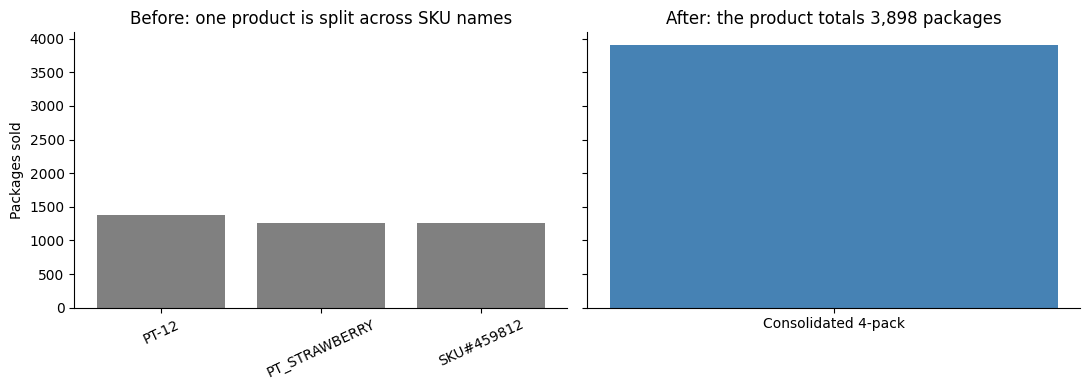

In [16]:
# Standardize SKU formatting.
catalog_clean = catalog.copy()
catalog_clean["sku"] = (
    catalog_clean["sku"].astype("string").str.strip().str.upper()
)

# Combine matching 4-pack variants; keep the 6-pack separate.
sku_mapping = {
    "PT-12": "POPTART-STRAWBERRY-4PK",
    "SKU#459812": "POPTART-STRAWBERRY-4PK",
    "PT_STRAWBERRY": "POPTART-STRAWBERRY-4PK",
    "POPTART-STRAW": "POPTART-STRAWBERRY-6PK"
}

catalog_clean["canonical_sku"] = (
    catalog_clean["sku"].replace(sku_mapping)
)

original_skus = catalog_clean["sku"].nunique()
canonical_products = catalog_clean["canonical_sku"].nunique()

# Compare the same valid quantities before and after mapping.
q2_sales = sales_clean.loc[
    sales_clean["quantity"].notna()
    & sales_clean["quantity"].ge(0)
].copy()

q2_sales["sku"] = (
    q2_sales["sku"].astype("string").str.strip().str.upper()
    .fillna("UNKNOWN")
)
q2_sales["canonical_sku"] = q2_sales["sku"].replace(sku_mapping)

before_total = q2_sales.groupby("sku")["quantity"].sum().sum()
after_total = q2_sales.groupby("canonical_sku")["quantity"].sum().sum()

assert before_total == after_total, "Unit totals changed!"

family_sizes = (
    catalog_clean.groupby("canonical_sku")["sku"]
    .nunique().sort_values(ascending=False)
)
largest_family = family_sizes.index[0]

family_sales = q2_sales[
    q2_sales["canonical_sku"].eq(largest_family)
]
fragmented = family_sales.groupby("sku")["quantity"].sum()
consolidated_total = fragmented.sum()

print("Original catalog SKUs:", original_skus)
print("Canonical products after initial mapping:", canonical_products)
print("Largest family by number of original SKUs:", largest_family)
print("Original SKUs in this family:", family_sizes.iloc[0])
print("Units before consolidation:", before_total)
print("Units after consolidation:", after_total)
print("PASS: consolidation preserved unit totals")
print("Note: counts are packages sold; 4-packs and 6-packs stay separate.")

display(fragmented.rename("units_before").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].bar(fragmented.index, fragmented.values, color="gray")
axes[0].set_title("Before: one product is split across SKU names")
axes[0].set_ylabel("Packages sold")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(["Consolidated 4-pack"], [consolidated_total],
            color="steelblue")
axes[1].set_title(
    f"After: the product totals {consolidated_total:,.0f} packages"
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Q2 answer: Consolidation reduced 45 SKUs to 43 products, combining three Pop-Tarts 4-pack SKUs into 3,898 packages sold. Total packages remained unchanged at 49,584, confirming the mapping preserved sales totals.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Source: https://archive-api.open-meteo.com/v1/archive
Data: live API retrieval of historical weather; no fallback
Timezone: America/New_York
Daily rows before join: 30
Daily rows after join: 30
Days in correlation: 30


,precipitation_sum,wind_speed_10m_max
Alcoholic Beverages,-0.256,0.374
Baby Products,-0.361,0.234
Breakfast Foods,-0.242,0.407
Electronics,-0.245,0.357
Emergency Supplies,-0.258,0.406
Games & Entertainment,-0.201,0.452
Grocery,-0.288,0.320
Health & Wellness,-0.233,0.376
Household Essentials,-0.234,0.395
Snacks,-0.165,0.233


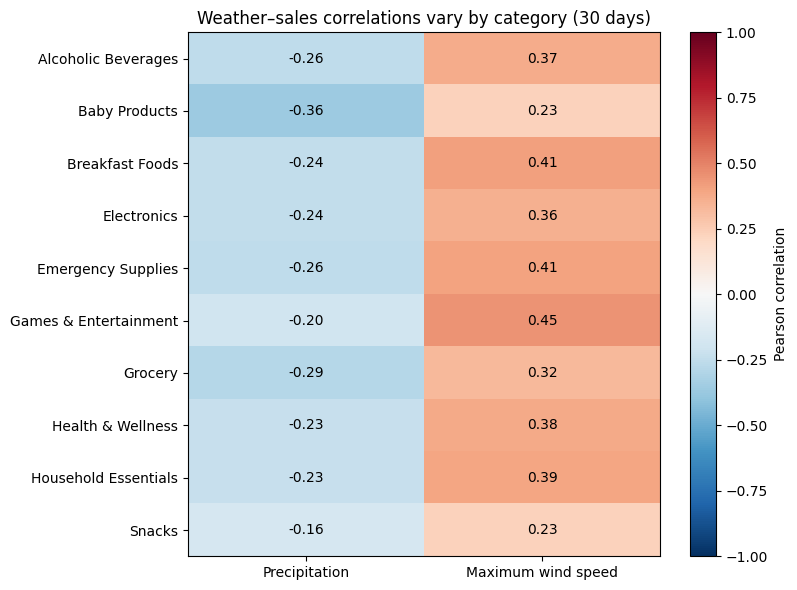

Caveat: one month and one weather location cannot establish causation or represent weather at every Florida store.


In [17]:
import requests
import matplotlib.pyplot as plt

# Historical Orlando weather, fetched directly from Open-Meteo.
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 28.54,
    "longitude": -81.38,
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "daily": "precipitation_sum,wind_speed_10m_max",
    "timezone": "America/New_York"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather = pd.DataFrame(response.json()["daily"])
weather = weather.rename(columns={"time": "date"})
weather["date"] = pd.to_datetime(weather["date"])
assert weather["date"].is_unique

# Sales timestamps are assumed to be local Florida time.
sales_daily = daily_units.copy()
sales_daily.index.name = "date"
sales_daily = sales_daily.reset_index()

rows_before = len(sales_daily)
joined = sales_daily.merge(
    weather, on="date", how="left", validate="one_to_one"
)
rows_after = len(joined)

q3_join_rows_preserved = rows_before == rows_after
assert q3_join_rows_preserved
assert joined[
    ["precipitation_sum", "wind_speed_10m_max"]
].notna().all().all()

categories = daily_units.columns.tolist()
weather_columns = ["precipitation_sum", "wind_speed_10m_max"]

correlation_data = joined[
    categories + weather_columns
].dropna()
q3_days_in_correlation = len(correlation_data)

correlations = correlation_data.corr().loc[
    categories, weather_columns
]

print("Source:", url)
print("Data: live API retrieval of historical weather; no fallback")
print("Timezone: America/New_York")
print("Daily rows before join:", rows_before)
print("Daily rows after join:", rows_after)
print("Days in correlation:", q3_days_in_correlation)
display(correlations.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(
    correlations.values, cmap="RdBu_r", vmin=-1, vmax=1,
    aspect="auto"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Precipitation", "Maximum wind speed"])
ax.set_yticks(range(len(categories)))
ax.set_yticklabels(categories)

for row in range(len(categories)):
    for col in range(2):
        ax.text(
            col, row, f"{correlations.iloc[row, col]:.2f}",
            ha="center", va="center"
        )

ax.set_title(
    f"Weather–sales correlations vary by category ({q3_days_in_correlation} days)"
)
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

print(
    "Caveat: one month and one weather location cannot establish "
    "causation or represent weather at every Florida store."
)

Q3 answer, with its caveat: The live API join preserved all 30 daily rows. Games & Entertainment had the strongest wind correlation (r = 0.452). However, 30 days of Orlando weather cannot prove causation or represent every Florida store.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

Q4 (stores and geography): I’m preparing to compare surge timing and size across stores and plan to finish over the next few days.

Q5 (signal or artifact): I’m preparing the SQLite investigation of the board-game surge and plan to finish over the next few days.

### Self-check

In [20]:
progress = {
    'q1_multiple': round(float(q1_multiple), 2),
    'q1_baseline_window': '2024-09-05 through 2024-09-18',
    'q2_canonical_products': int(canonical_products),
    'q3_join_rows_preserved': bool(q3_join_rows_preserved),
    'q3_days_in_correlation': q3_days_in_correlation,
    'charts_with_message_titles': 3,
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 4.08
PASS - q1_baseline_window = 2024-09-05 through 2024-09-18
PASS - q2_canonical_products = 43
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug. Combining three Pop-Tarts SKUs revealed 3,898 packages sold. I verified that consolidation preserved the overall total of 49,584 packages.

**b)** One number you reported that you are least confident in, and why. I’m least confident in the wind correlation of 0.452 because it uses only 30 days of Orlando weather for stores across Florida.